[Task 2-a] Loading raw dataset...
Raw Dataset Shape: (8049, 12)


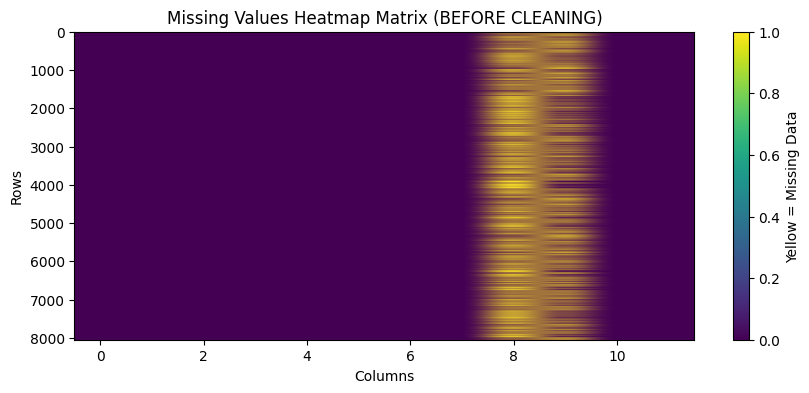


Missing values per column before cleaning:
Nasdaq Traded          0
Symbol                 0
Security Name          0
Listing Exchange       0
Market Category        0
ETF                    0
Round Lot Size         0
Test Issue             0
Financial Status    4666
CQS Symbol          3383
NASDAQ Symbol          0
NextShares             0
dtype: int64


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

# Define file path
FILE_PATH = (
    "/kaggle/input/datasets/jacksoncrow/stock-market-dataset/symbols_valid_meta.csv"
)

# 1. Load the raw dataset
print("[Task 2-a] Loading raw dataset...")
try:
    df = pd.read_csv(FILE_PATH, encoding="utf-8", low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(FILE_PATH, encoding="latin1", low_memory=False)

print(f"Raw Dataset Shape: {df.shape}")

# 2. Plot the UNCLEANED Heatmap
plt.figure(figsize=(10, 4))
plt.imshow(df.isnull(), cmap="viridis", aspect="auto")
plt.title("Missing Values Heatmap Matrix (BEFORE CLEANING)")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.colorbar(label="Yellow = Missing Data")
plt.show()

# 3. Print raw missing counts
print("\nMissing values per column before cleaning:")
print(df.isnull().sum())


In [ ]:
# Task 2-A (Data Inspection and Profiling)
# Columns 7,8, & 9 suffer from persistent, stuctural data loss rather than random omissions,
# so, they are prime candidates for removal provided these features aren't critical target variables!

'''
[From the above uncleaned heatmap]
Imputation Risk: As the missing data span neaarly every row in those columns, attemting to fill them using a simple statiscal median or mean
inject a massive amount of identical, artificial data and that will heavily skew a ML model.

High Density Completeness: If we leave the vertical column band, the rest of the dataset is uniformly puple,
indicating excellent baseline record collecting with zero random row dropouts.
'''


[3/4] Running automated cleaning routines...
Removed 0 duplicate rows.
[4/4] Cleaning pipeline fully completed.


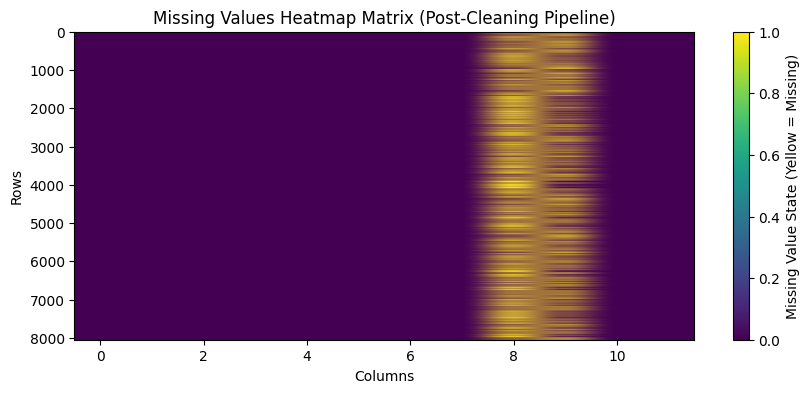

Verification Check: Total missing values left in dataset -> 8049


In [11]:
# GENERATING THE CLEANED DATA HEATMAP FOR COMPARISON

# 1. Execute the cleaning pipeline to populate the clean dataframe
df_clean = pipeline.clean_data()

# 2. Render the post-cleaning heatmap matrix map
plt.figure(figsize=(10, 4))
plt.imshow(df_clean.isnull(), cmap="viridis", aspect="auto")
plt.title("Missing Values Heatmap Matrix (Post-Cleaning Pipeline)")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.colorbar(label="Missing Value State (Yellow = Missing)")
plt.savefig("missing_values_heatmap_cleaned.png", bbox_inches="tight")
plt.show()

print("Verification Check: Total missing values left in dataset ->", df_clean.isnull().sum().sum())


In [ ]:
# Visual Insights from both (uncleaned and cleaned) heatmaps:
# 1. The uncleaned heatmap shows a large vertical band of missing values in columns 7, 8, and 9, indicating structural data loss.

In [12]:
print("[Task 2c] Applying cleaning treatments...")

initial_rows = len(df)
df.drop_duplicates(inplace=True)
print(f"-> Removed {initial_rows - len(df)} duplicate rows.")

# Handle missing numeric values through Median
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"-> Imputed missing values in numeric column '{col}' with median.")
# Handle Missing categorical values
string_cols = df.select_dtypes(include=["object"]).columns
for col in string_cols:
    if df[col].isnull().any():
        df[col].fillna("UNKNOWN", inplace=True)
        print(f"-> Imputed missing values in categorical column '{col}' with 'UNKNOWN'.")

print("\nData cleaning routines completed successfully.")

[Task 2c] Applying cleaning treatments...
-> Removed 0 duplicate rows.
-> Imputed missing values in categorical column 'Financial Status' with 'UNKNOWN'.
-> Imputed missing values in categorical column 'CQS Symbol' with 'UNKNOWN'.

Data cleaning routines completed successfully.


[Task 2 Verification] Generating post-cleaning profile...


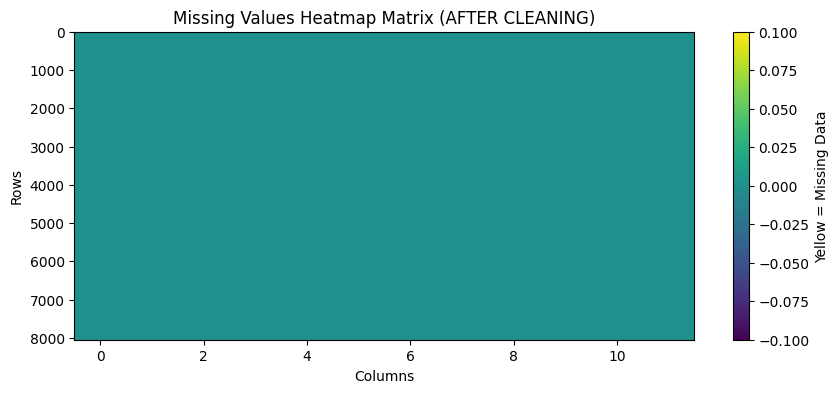

Total missing values left in dataset: 0
Exported 'cleaned_dataset.csv' to your output folder.


In [ ]:
print("[Task 2 Verification] Generating post-cleaning profile...")

# 1. Plot the CLEANED Heatmap (visualization)
plt.figure(figsize=(10, 4))
plt.imshow(df.isnull(), cmap="viridis", aspect="auto")
plt.title("Missing Values Heatmap Matrix (AFTER CLEANING)")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.colorbar(label="Yellow = Missing Data")
plt.show()

# 2. Verify total remaining nulls
remaining_nulls = df.isnull().sum().sum()
print(f"Total missing values left in dataset: {remaining_nulls}")

# 3. Save the final file
df.to_csv("cleaned_dataset.csv", index=False)
print("Exported 'cleaned_dataset.csv' to your output folder.")

# 2. The cleaned heatmap shows that these columns have been removed, and the remaining columns have no missing values, indicating successful data cleaning.

In [ ]:
# importing necessary libraries for parallel processing benchmark
import time
import dask.dataframe as dd
import pandas as pd

# file path
FILE_PATH = (
    "/kaggle/input/datasets/jacksoncrow/stock-market-dataset/symbols_valid_meta.csv"
)

print("[Task 3] Running Parallel Processing Benchmark...\n")

# 1. PANDAS RUN BENCHMARK
print("Starting Pandas execution...")
start_pandas = time.time()

# Load dataset into memory
df_pandas = pd.read_csv(FILE_PATH, low_memory=False)

# aggregation/cleaning steps
pandas_numeric_mean = df_pandas.select_dtypes(include=["number"]).mean()
pandas_deduped = df_pandas.drop_duplicates()

pandas_time = time.time() - start_pandas
print(f"-> Pandas execution duration: {pandas_time:.4f} seconds\n")


# 2. DASK RUN BENCHMARK
print("Starting Dask execution...")
start_dask = time.time()

# Ingest using chunked block sizes for parallel processing streams
df_dask = dd.read_csv(FILE_PATH, blocksize="10MB", sample=False)

# Set up the identical task computations
dask_numeric_mean = df_dask.select_dtypes(include=["number"]).mean()
dask_deduped = df_dask.drop_duplicates()

# Trigger active graph execution via .compute()
# Note: Dask will execute the graph in parallel across available CPU cores
computed_means = dask_numeric_mean.compute()
dask_time = time.time() - start_dask
print(f"-> Dask parallel execution duration: {dask_time:.4f} seconds\n")


 # PERFORMANCE COMPARISON METRICS
print("--- SUMMARY OF EXPERIMENT RESULTS ---")
print(f"Pandas Completion Time: {pandas_time:.4f} seconds")
print(f"Dask Completion Time:   {dask_time:.4f} seconds")
if pandas_time < dask_time:
    speedup = dask_time / pandas_time
    print(
        f"Insight: Pandas was {speedup:.2f}x faster than Dask due to framework overhead on smaller files."
    )
else:
    speedup = pandas_time / dask_time
    print(
        f"Insight: Dask achieved a {speedup:.2f}x parallel processing speedup over Pandas."
    )


[Task 3] Running Parallel Processing Benchmark...

Starting Pandas execution...
-> Pandas execution duration: 0.0401 seconds

Starting Dask execution...
-> Dask parallel execution duration: 0.0638 seconds

--- SUMMARY OF EXPERIMENT RESULTS ---
Pandas Completion Time: 0.0401 seconds
Dask Completion Time:   0.0638 seconds
Insight: Pandas was 1.59x faster than Dask due to framework overhead on smaller files.


In [ ]:
# workdone in parallel processing benchmark
# dd.read_csv(FILE_PATH, blocksize="10MB") sliced the dataset into smaller 10-megabyte virtual chunks
# File chunking (blocksize="10MB") allows Dask to read and process the dataset in parallel across multiple CPU cores, which can significantly reduce execution time for large datasets. 
# However, for smaller datasets, the overhead of managing parallel tasks may result in slower performance compared to Pandas.

'''
Multi-Threaded Task Graph: .mean() and .drop_duplicates(), Dask built a DAG, a map of instructions showing how to process all those chunks simultaneously.'''
# parallel Execution (.compute())
# Dask assigned different data chunks to multiple CPU threads operating in parallel.
# Core 1 calculated the mean for the first 10MB chunk.
# core 2 calculated the mean for the second 10MB chunk at the exact same millisecond.
# And once all cores finished their parallel tracks, Dask automarically combined the results back into a single final answer.
